In [23]:
import polars as pl
import MDAnalysis as mda


rmsd = pl.read_parquet(
    "../../data/sourced_antibody_v1/no_antibody/assay_scaffold_simple_metrics.parquet"
).filter(pl.col("mean_pae").is_not_null())

rmsd_summary = rmsd.group_by("id").agg(
    pl.len().alias("attempts"),
    pl.col("epitope_chunks").first(),
    pl.col("epitope_chunk_resindices").first(),
)

rmsd_filt = (
    rmsd.filter(
        pl.col("mean_pae") < 5,
        pl.col("overall_rmsd") <= 2,
        pl.col("epitope_chunk_rmsd_vs_mpnn") <= 1,
        pl.col("af3_clash_resindices").list.len() == 0,
    )
    .group_by("id")
    .agg(
        pl.len().alias("n_success"),
    )
)

rmsd_summary = (
    rmsd_summary.join(rmsd_filt, on="id", how="left")
    .fill_null(0)
    .with_columns(
        (pl.col("n_success") / pl.col("attempts") * 100).alias("success_rate")
    )
)

filter_names = [
    "mean_pae",
    "overall_rmsd",
    "epitope_chunk_rmsd",
    "af3_clash_resindices",
]

for filt, name in zip(
    [
        (pl.col("mean_pae") < 5,),
        (pl.col("overall_rmsd") <= 2,),
        (pl.col("epitope_chunk_rmsd_vs_mpnn") <= 1,),
        (pl.col("af3_clash_resindices").list.len() == 0,),
    ],
    filter_names,
):
    rmsd_tmp = rmsd.filter(filt)
    rmsd_tmp = rmsd_tmp.group_by("id").agg(pl.len().alias(f"n_success_{name}"))
    rmsd_summary = (
        rmsd_summary.join(rmsd_tmp, on="id", how="left")
        .fill_null(0)
        .with_columns(
            (pl.col(f"n_success_{name}") / pl.col("attempts") * 100).alias(
                f"success_rate_{name}"
            )
        )
    )

rmsd_summary = rmsd_summary.sort(by="success_rate", descending=True)

pl.Config.set_tbl_rows(59)

polars.config.Config

## Which metric is the constraint?


(<Figure size 4720x500 with 1 Axes>,
 <Axes: title={'center': 'Success rates by scaffold ID'}, ylabel='Success rate'>)

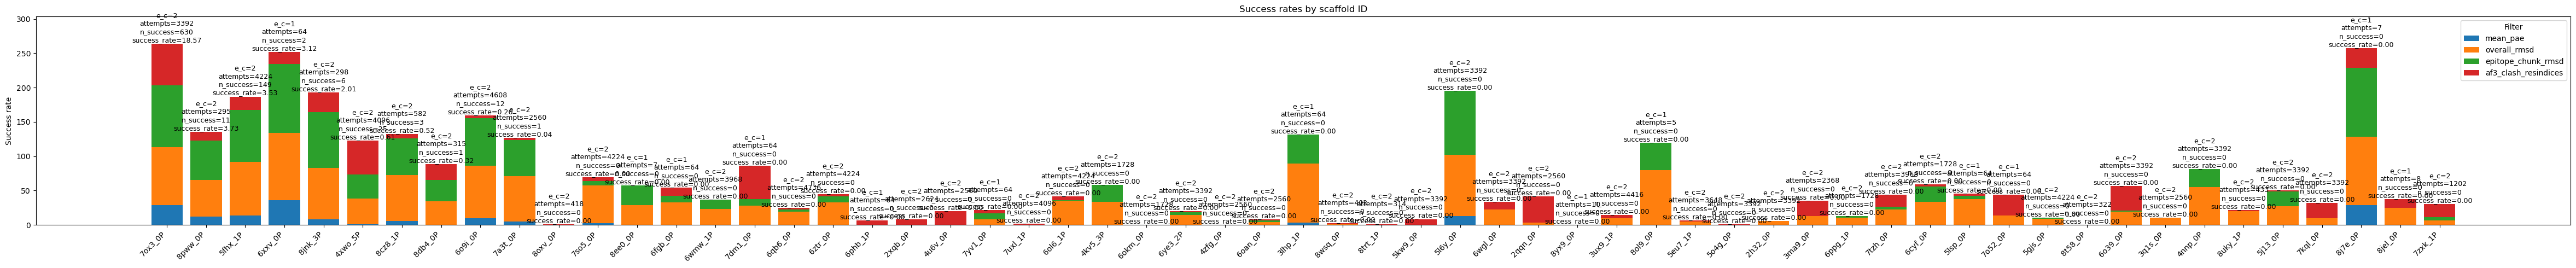

In [2]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt


def plot_stacked_success_rates(df: pl.DataFrame, title=""):
    filter_names = [
        "mean_pae",
        "overall_rmsd",
        "epitope_chunk_rmsd",
        "af3_clash_resindices",
    ]
    cols = [f"success_rate_{n}" for n in filter_names]
    ids = df.get_column("id").to_list()
    x = np.arange(len(ids))
    vals = [df.get_column(c).to_numpy() for c in cols]
    attempts = df.get_column("attempts").to_numpy()
    n_success = df.get_column("n_success").to_numpy()
    success_rate = df.get_column("success_rate").to_numpy()
    e_c = df.get_column("epitope_chunks").to_numpy()
    fig, ax = plt.subplots(figsize=(max(8, 0.8 * len(ids)), 5))
    base = np.zeros(len(ids))
    handles = []
    for v in vals:
        h = ax.bar(x, v, bottom=base)
        handles.append(h[0])
        base += v
    totals = base
    for i in range(len(ids)):
        ax.text(
            i,
            totals[i] + 0.02,
            f"e_c={int(e_c[i])}\nattempts={int(attempts[i])}\nn_success={int(n_success[i])}\nsuccess_rate={success_rate[i]:.2f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )
    ax.set_xticks(x)
    ax.set_xticklabels(ids, rotation=45, ha="right")
    ax.set_ylabel("Success rate")
    ax.set_title(title)
    ax.legend(handles, filter_names, title="Filter")
    ax.set_ylim(0, max(1.0, totals.max() * 1.15 + 0.05))
    plt.tight_layout()
    return fig, ax


plot_stacked_success_rates(rmsd_summary, title="Success rates by scaffold ID")

## Visualize some examples


In [ ]:
from mdaf3.AF3OutputParser import AF3Output
import MDAnalysis as mda
from MDAnalysis.analysis import rms
from MDAnalysis.analysis.align import alignto
import numpy as np
from pathlib import Path

true_dir = Path("../../data/abdb/complex_pdbfiles/cleaned")
pred_dir = Path("../../data/sourced_antibody_v1/no_antibody/af3_predictions")
mpnn_dir = Path("../../data/sourced_antibody_v1/no_antibody/proteinmpnn")


def characterize_ec(row, af3_dir, mpnn_dir, true_dir):
    af3_output = AF3Output(af3_dir / row["assay_scaffolded_epitope_id"])
    af3_u = af3_output.get_mda_universe()
    af3_ris = row["assay_scaffolded_epitope_chunk_resindices"]

    mpnn_u = mda.Universe(
        ((mpnn_dir / row["id"]) / str(row["contig_id"]))
        / (
            row["id"]
            + "_"
            + str(row["rfd_id"])
            + "_fixed_dldesign_"
            + str(row["mpnn_id"])
            + ".pdb"
        )
    )
    mpnn_ris = row["scaffolded_epitope_chunk_resindices"]

    true_u = mda.Universe(true_dir / (row["id"] + ".pdb"))
    true_ris = row["epitope_chunk_resindices"]

    alignto(
        mpnn_u.residues[mpnn_ris].atoms.select_atoms("backbone"),
        true_u.residues[true_ris].atoms.select_atoms("backbone"),
    )

    # print(mpnn_u.residues[mpnn_ris].atoms.select_atoms("name CA").positions[:10])
    # print(true_u.residues[true_ris].atoms.select_atoms("name CA").positions[:10])

    mpnn_combined_u = mda.Merge(
        mpnn_u.atoms, true_u.atoms.select_atoms("segid B or segid C")
    )
    # mpnn_combined_u.atoms.write("mpnn_combined.pdb")

    tmp_boolmask = np.full(len(mpnn_u.residues), False)
    tmp_boolmask[mpnn_ris] = True
    unintended_res = mpnn_combined_u.select_atoms("segid A").residues[~tmp_boolmask]

    row["mpnn_clash_resindices"] = list(
        unintended_res.atoms.select_atoms(
            "segid A and (not name H*) and around 4 ((segid B or segid C) and (not name H*))"
        ).residues.resindices
    )

    alignto(
        af3_u.residues[af3_ris].atoms.select_atoms("backbone"),
        true_u.residues[true_ris].atoms.select_atoms("backbone"),
    )
    af3_u.atoms.chainIDs = ["D"] * len(af3_u.atoms)
    af3_combined_u = mda.Merge(af3_u.atoms, true_u.atoms)
    af3_combined_u.atoms.write(
        f"/tgen_labs/altin/alphafold3/workspace/episcaf-experiments/tmp/superimpose_example/{row['id']}.pdb"
    )
    af3_combined_u = mda.Merge(
        af3_u.atoms, true_u.atoms.select_atoms("segid B or segid C")
    )
    tmp_boolmask = np.full(len(af3_u.residues), False)
    tmp_boolmask[af3_ris] = True
    unintended_res = af3_combined_u.select_atoms("segid A").residues[~tmp_boolmask]
    # print(unintended_res)
    # print(unintended_res.atoms.select_atoms("segid A and (not name H*)"))

    l = list(
        unintended_res.atoms.select_atoms(
            "segid A and (not name H*) and around 4 ((segid B or segid C) and (not name H*))"
        ).residues.resindices
    )

    if len(l) > 0:
        print("Clash dectected")

    row["af3_clash_resindices"] = l

    return row

In [18]:
from mdaf3.FeatureExtraction import serial_apply

examples = (
    rmsd.filter(
        pl.col("mean_pae") < 5,
        pl.col("overall_rmsd") <= 2,
        pl.col("epitope_chunk_rmsd_vs_mpnn") <= 1,
        pl.col("af3_clash_resindices").list.len() == 0,
    )
    .group_by("id")
    .first()
)

_ = serial_apply(examples, characterize_ec, pred_dir, mpnn_dir, true_dir)

Processing rows:   0%|          | 0/10 [00:00<?, ?it/s]/home/lwoods/miniconda3/envs/episcaf-experiments/lib/python3.13/site-packages/MDAnalysis/coordinates/MMCIF.py:139: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/home/lwoods/miniconda3/envs/episcaf-experiments/lib/python3.13/site-packages/MDAnalysis/coordinates/PDB.py:465: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn("1 A^3 CRYST1 record,"
/home/lwoods/miniconda3/envs/episcaf-experiments/lib/python3.13/site-packages/MDAnalysis/coordinates/PDB.py:789: UserWarning: Unit cell dimensions not found. CRYST1 record set to unitary values.
  warnings.warn("Unit cell dimensions not found. "
/home/lwoods/miniconda3/envs/episcaf-experiments/lib/python3.13/site-packages/MDAnalysis/coordinates/PDB.py:1166: UserWarning: Found no information for attr: 'formalcharges' Using default value of '0'


Characteristics to investigate:

- helical %, loop %, etc
- composition within each chunk
- total num epitope chunk resindices
- total distance spanned by the epitope residues


In [44]:
from MDAnalysis.analysis.dssp import DSSP
from MDAnalysis.analysis.distances import self_distance_array


def characterize_ec(row, af3_dir, mpnn_dir, true_dir):
    # af3_output = AF3Output(af3_dir / row["assay_scaffolded_epitope_id"])
    # af3_u = af3_output.get_mda_universe()
    # af3_ris = row["assay_scaffolded_epitope_chunk_resindices"]

    # mpnn_u = mda.Universe(
    #     ((mpnn_dir / row["id"]) / str(row["contig_id"]))
    #     / (
    #         row["id"]
    #         + "_"
    #         + str(row["rfd_id"])
    #         + "_fixed_dldesign_"
    #         + str(row["mpnn_id"])
    #         + ".pdb"
    #     )
    # )
    # mpnn_ris = row["scaffolded_epitope_chunk_resindices"]

    true_u = mda.Universe(true_dir / (row["id"] + ".pdb"))
    true_ris = row["epitope_chunk_resindices"]

    dssp = DSSP(true_u.atoms).run().results.dssp_ndarray

    row["per_loop"] = dssp[0, true_ris, 0].sum() / len(true_ris)
    row["per_helix"] = dssp[0, true_ris, 1].sum() / len(true_ris)
    row["e_c_len"] = len(row["epitope_chunk_resindices"])

    row["max_internal_dist"] = self_distance_array(
        true_u.residues[true_ris].atoms.positions
    ).max()

    # alignto(
    #     mpnn_u.residues[mpnn_ris].atoms.select_atoms("backbone"),
    #     true_u.residues[true_ris].atoms.select_atoms("backbone"),
    # )

    # # print(mpnn_u.residues[mpnn_ris].atoms.select_atoms("name CA").positions[:10])
    # # print(true_u.residues[true_ris].atoms.select_atoms("name CA").positions[:10])

    # mpnn_combined_u = mda.Merge(
    #     mpnn_u.atoms, true_u.atoms.select_atoms("segid B or segid C")
    # )
    # # mpnn_combined_u.atoms.write("mpnn_combined.pdb")

    # tmp_boolmask = np.full(len(mpnn_u.residues), False)
    # tmp_boolmask[mpnn_ris] = True
    # unintended_res = mpnn_combined_u.select_atoms("segid A").residues[~tmp_boolmask]

    # row["mpnn_clash_resindices"] = list(
    #     unintended_res.atoms.select_atoms(
    #         "segid A and (not name H*) and around 4 ((segid B or segid C) and (not name H*))"
    #     ).residues.resindices
    # )

    # alignto(
    #     af3_u.residues[af3_ris].atoms.select_atoms("backbone"),
    #     true_u.residues[true_ris].atoms.select_atoms("backbone"),
    # )
    # af3_u.atoms.chainIDs = ["D"] * len(af3_u.atoms)
    # af3_combined_u = mda.Merge(af3_u.atoms, true_u.atoms)
    # af3_combined_u.atoms.write(
    #     f"/tgen_labs/altin/alphafold3/workspace/episcaf-experiments/tmp/superimpose_example/{row['id']}.pdb"
    # )
    # af3_combined_u = mda.Merge(
    #     af3_u.atoms, true_u.atoms.select_atoms("segid B or segid C")
    # )
    # tmp_boolmask = np.full(len(af3_u.residues), False)
    # tmp_boolmask[af3_ris] = True
    # unintended_res = af3_combined_u.select_atoms("segid A").residues[~tmp_boolmask]
    # # print(unintended_res)
    # # print(unintended_res.atoms.select_atoms("segid A and (not name H*)"))

    # l = list(
    #     unintended_res.atoms.select_atoms(
    #         "segid A and (not name H*) and around 4 ((segid B or segid C) and (not name H*))"
    #     ).residues.resindices
    # )

    # if len(l) > 0:
    #     print("Clash dectected")

    # row["af3_clash_resindices"] = l

    return row

In [45]:
ec_char = serial_apply(rmsd_summary, characterize_ec, pred_dir, mpnn_dir, true_dir)
ec_char

Processing rows:   0%|          | 0/59 [00:00<?, ?it/s]/home/lwoods/miniconda3/envs/episcaf-experiments/lib/python3.13/site-packages/MDAnalysis/coordinates/PDB.py:465: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn("1 A^3 CRYST1 record,"
/home/lwoods/miniconda3/envs/episcaf-experiments/lib/python3.13/site-packages/MDAnalysis/analysis/base.py:542: UserWarning: Reader has no dt information, set to 1.0 ps
  self.times[idx] = ts.time
Processing rows: 100%|██████████| 59/59 [00:07<00:00,  7.71it/s]


id,attempts,epitope_chunks,epitope_chunk_resindices,n_success,success_rate,n_success_mean_pae,success_rate_mean_pae,n_success_overall_rmsd,success_rate_overall_rmsd,n_success_epitope_chunk_rmsd,success_rate_epitope_chunk_rmsd,n_success_af3_clash_resindices,success_rate_af3_clash_resindices,per_loop,per_helix,e_c_len,max_internal_dist
str,i64,i64,list[i64],i64,f64,i64,f64,i64,f64,i64,f64,i64,f64,f64,f64,i64,f64
"""7ox3_0P""",3392,2,"[5, 6, … 74]",630,18.573113,978,28.832547,2870,84.610849,3035,89.475236,2064,60.849057,0.047619,0.952381,21,26.639028
"""8pww_0P""",295,2,"[49, 50, … 136]",11,3.728814,35,11.864407,159,53.898305,168,56.949153,38,12.881356,0.0,1.0,27,28.784007
"""5fhx_1P""",4224,2,"[13, 14, … 73]",149,3.527462,586,13.873106,3302,78.172348,3188,75.473485,820,19.412879,0.066667,0.933333,15,22.307229
"""6xxv_0P""",64,1,"[62, 63, … 83]",2,3.125,23,35.9375,63,98.4375,64,100.0,11,17.1875,0.227273,0.772727,22,23.706708
"""8jnk_3P""",298,2,"[27, 28, … 88]",6,2.013423,24,8.053691,223,74.832215,242,81.208054,85,28.52349,0.115385,0.884615,26,27.335975
"""4xwo_5P""",4096,2,"[196, 197, … 256]",25,0.610352,28,0.683594,1556,37.988281,1427,34.838867,2008,49.023438,0.290323,0.677419,31,30.861005
"""8cz8_1P""",582,2,"[106, 107, … 143]",3,0.515464,32,5.498282,393,67.525773,307,52.749141,40,6.872852,0.1875,0.8125,16,24.888483
"""8db4_0P""",315,2,"[5, 6, … 61]",1,0.31746,1,0.31746,108,34.285714,97,30.793651,72,22.857143,0.318182,0.681818,22,30.67495
"""6o9i_0P""",4608,2,"[5, 6, … 53]",12,0.260417,432,9.375,3544,76.909722,3192,69.270833,167,3.624132,0.263158,0.736842,19,32.506799


In [38]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr


def plot_scatter_with_spearman(x, y, title=None, ax=None, s=24, alpha=0.8):
    """
    Scatter-plot x vs y and show Spearman correlation.

    Parameters
    ----------
    x, y : array-like
        1D arrays of equal length.
    title : str, optional
        Figure title.
    ax : matplotlib.axes.Axes, optional
        Existing axes to draw on. If None, creates a new figure.
    s : float
        Marker size.
    alpha : float
        Marker alpha.

    Returns
    -------
    fig, ax, rho, p : (matplotlib.figure.Figure, matplotlib.axes.Axes, float, float)
        Figure/axes handles and Spearman correlation (rho) with p-value.
    """
    x = np.asarray(x).ravel()
    y = np.asarray(y).ravel()
    m = np.isfinite(x) & np.isfinite(y)

    rho, p = spearmanr(x[m], y[m], nan_policy="omit")

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4))
    else:
        fig = ax.figure

    ax.scatter(x[m], y[m], s=s, alpha=alpha)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    if title:
        ax.set_title(title)

    # Annotate Spearman stats in the top-left corner
    ax.text(
        0.02,
        0.98,
        f"Spearman ρ = {rho:.3f}\np = {p:.3g}\nn = {m.sum()}",
        transform=ax.transAxes,
        ha="left",
        va="top",
        bbox=dict(facecolor="white", alpha=0.7, edgecolor="none"),
    )

    return fig, ax, rho, p

(<Figure size 600x400 with 1 Axes>,
 <Axes: xlabel='x', ylabel='y'>,
 np.float64(-0.40702263370830477),
 np.float64(0.0013778368193212366))

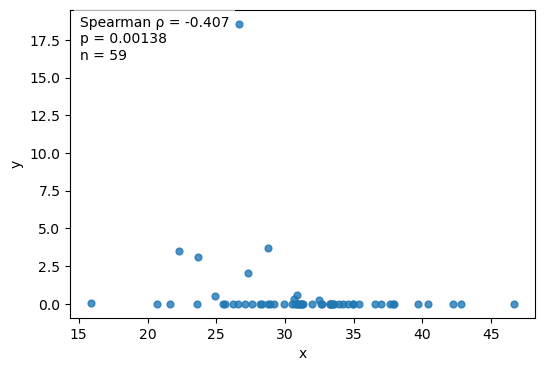

In [46]:
plot_scatter_with_spearman(ec_char["max_internal_dist"], ec_char["success_rate"])

In [57]:
import numpy as np
from scipy import stats, linalg

def evaluate_predictors(X, y, k_folds=5, use_ranks=False, random_state=0):
    """
    Evaluate how well columns of X predict y.

    Parameters
    ----------
    X : array-like, shape (n_samples, n_features)
    y : array-like, shape (n_samples,)
    k_folds : int, number of CV folds (>=2)
    use_ranks : bool, if True, regress on rank-transformed X and y (Spearman-like)
    random_state : int, RNG seed for CV splits

    Returns
    -------
    results : dict
        {
          "pearson": [(r, p), ...] per feature vs y,
          "spearman": [(rho, p), ...] per feature vs y,
          "coefficients": beta (including intercept as beta[0]),
          "r2": float,
          "adj_r2": float,
          "rmse": float,
          "cv_r2_mean": float,
          "cv_r2_std": float
        }
    """
    X = np.asarray(X, float)
    y = np.asarray(y, float).ravel()
    n, p = X.shape

    # Mask finite
    m = np.isfinite(X).all(axis=1) & np.isfinite(y)
    X, y = X[m], y[m]
    n, p = X.shape

    # Per-feature correlations
    pearson = [stats.pearsonr(X[:, j], y) for j in range(p)]
    spearman = [stats.spearmanr(X[:, j], y) for j in range(p)]

    # Optionally rank-transform (monotonic relation; akin to Spearman regression)
    if use_ranks:
        X = np.column_stack([stats.rankdata(X[:, j]) for j in range(p)])
        y = stats.rankdata(y)

    # Add intercept and fit via least squares
    Xd = np.column_stack([np.ones(n), X])  # intercept first
    beta, _, _, _ = linalg.lstsq(Xd, y)  # solves min ||Xd @ beta - y||

    yhat = Xd @ beta
    sse = np.sum((y - yhat) ** 2)
    sst = np.sum((y - y.mean()) ** 2)
    r2 = 1.0 - sse / sst if sst > 0 else np.nan
    adj_r2 = (
        1.0 - (1.0 - r2) * (n - 1) / (n - (p + 1))
        if n > p + 1 and np.isfinite(r2)
        else np.nan
    )
    rmse = np.sqrt(sse / n)

    # Simple K-fold CV R^2
    rng = np.random.default_rng(random_state)
    idx = rng.permutation(n)
    folds = np.array_split(idx, k_folds)
    cv_r2 = []
    for k in range(k_folds):
        test = folds[k]
        train = np.concatenate([folds[i] for i in range(k_folds) if i != k])
        beta_k, _, _, _ = linalg.lstsq(Xd[train], y[train])
        yhat_k = Xd[test] @ beta_k
        sse_k = np.sum((y[test] - yhat_k) ** 2)
        sst_k = np.sum((y[test] - y[test].mean()) ** 2)
        r2_k = 1.0 - sse_k / sst_k if sst_k > 0 else np.nan
        cv_r2.append(r2_k)
    cv_r2 = np.array(cv_r2, float)

    return {
        "pearson": pearson,
        "spearman": spearman,
        "coefficients": beta,  # beta[0] is intercept; beta[1:] map to X columns
        "r2": r2,
        "adj_r2": adj_r2,
        "rmse": rmse,
        "cv_r2_mean": np.nanmean(cv_r2),
        "cv_r2_std": (
            np.nanstd(cv_r2, ddof=1) if np.isfinite(cv_r2).sum() > 1 else np.nan
        ),
    }


evaluate_predictors(
    ec_char.select("max_internal_dist", "per_helix", "e_c_len").to_numpy(),
    ec_char.select("success_rate").to_series().to_numpy(),
    use_ranks=True
)

{'pearson': [PearsonRResult(statistic=np.float64(-0.19753858906521538), pvalue=np.float64(0.133697588719194)),
  PearsonRResult(statistic=np.float64(0.31894662326716716), pvalue=np.float64(0.013811304495417565)),
  PearsonRResult(statistic=np.float64(-0.10623163316570762), pvalue=np.float64(0.42325234229267883))],
 'spearman': [SignificanceResult(statistic=np.float64(-0.40702263370830477), pvalue=np.float64(0.0013778368193212366)),
  SignificanceResult(statistic=np.float64(0.4273693787670441), pvalue=np.float64(0.000735576318778529)),
  SignificanceResult(statistic=np.float64(-0.2415050172439838), pvalue=np.float64(0.06536916971693953))],
 'coefficients': array([ 2.96880742e+01, -2.48103072e-01,  2.86946266e-01, -2.84456670e-02]),
 'r2': np.float64(0.35106034448655565),
 'adj_r2': np.float64(0.31566363600400416),
 'rmse': np.float64(8.966745419626596),
 'cv_r2_mean': np.float64(0.1383228283061823),
 'cv_r2_std': np.float64(0.4833767647526936)}